# Benchmark Evaluation of Open-Source LLMs with Prompt Engineering

Evaluates **TinyLlama v1.1, Qwen2.5-3B-Instruct, DeepSeek-R1-Distill-Qwen-1.5B and Qwen3-4B-Instruct-2507** on **CommonsenseQA, OpenBookQA and PIQA**, comparing a baseline prompt with an engineered prompt (role + few-shot examples + output constraint).

Ran on Google Colab with an NVIDIA A100 GPU. Course project for AI6130 (Large Language Models), NTU Singapore.

**Notebook structure**
1. Setup
2. Warm-up: the course's example evaluation code
3. Pilot run (N = 50 per dataset)
4. Final run (N = 200 per dataset) — results reported in the README

## 1. Setup

In [ ]:
!pip install -q transformers datasets accelerate bitsandbytes seaborn

In [ ]:
# !huggingface-cli login

## 2. Warm-up: example evaluation code
Loads the `Open-Style/Open-LLM-Benchmark` dataset and runs the provided example `infer_llm` on CommonsenseQA with TinyLlama. The raw free-text answers are hard to parse, which motivates the answer-extraction and prompt changes below.

In [ ]:
import datasets
import json

eval_set = datasets.load_dataset("Open-Style/Open-LLM-Benchmark", "questions")
grouped_datasets = {}
for example in eval_set['train']:
    dataset = example["dataset"]
    if dataset not in grouped_datasets:
        grouped_datasets[dataset] = []
    grouped_datasets[dataset].append(example)

In [ ]:
grouped_datasets.keys()

dict_keys(['ARC', 'CommonsenseQA', 'Hellaswag', 'MMLU', 'MedMCQA', 'OpenbookQA', 'Winogrande', 'piqa', 'race'])

In [ ]:
from transformers import AutoTokenizer,AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("TinyLlama/TinyLlama_v1.1")
model = AutoModelForCausalLM.from_pretrained("TinyLlama/TinyLlama_v1.1", device_map="auto")

### You have to change your using model and tokenizer here

In [ ]:
import time
import tqdm

# Ensure model is running on the GPU if available
device = model.device
# model = model.to(device)

# Define a function for inference
def infer_llm(sample):
    question = sample["question"]
    options = sample["options"]
    prompt = f"{question}\n"
    for option in options:
        prompt += f"{option['label']}: {option['text']}\n"

    ### You can change the prompt to to suit the model you are using.
    # Example:
    # Answer in A/B/C/D:
    # Answer in a single word or phrase:

    prompt += "Answer: "

    # Tokenize the input
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    # Generate the output
    outputs = model.generate(
        inputs["input_ids"],
        max_length=len(inputs["input_ids"][0]) + 5, ### You may refer to the max_new_tokens parameter to speed up inference.
        num_return_sequences=1,
        attention_mask=inputs["attention_mask"],
        pad_token_id=tokenizer.eos_token_id,
        do_sample=True,
    )

    # Decode the output
    decoded_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    answer = decoded_output.split("Answer:")[-1].strip()
    return answer

# Define the evaluation function
def evaluate_samples(samples):
    correct = 0
    total = len(samples)
    predictions = []

    s = time.time()
    for sample in tqdm.tqdm(samples):
        predicted_answer = infer_llm(sample)
        predictions.append(predicted_answer)

        clean_answer = predicted_answer.strip()
        if len(clean_answer) > 0 and clean_answer[0].upper() == sample["answerKey"].upper():
            correct += 1
    e = time.time()
    print("Time:",e - s)
    accuracy = correct / total * 100
    return predictions, accuracy

# Evaluate the samples
predictions, accuracy = evaluate_samples(grouped_datasets['CommonsenseQA'])

In [ ]:
# Print results
for i, sample in enumerate(grouped_datasets['CommonsenseQA']):
    print(f"Question: {sample['question']}")
    print(f"Predicted Answer: {predictions[i]}")
    print(f"Correct Answer: {sample['answerKey']}\n")

print(f"Accuracy: {accuracy:.2f}%")

Question: A revolving door is convenient for two direction travel, but it also serves as a security measure at a what?
Predicted Answer: Bank
A: library
Correct Answer: A

Question: What do people aim to do at work?
Predicted Answer: 1) A,
Correct Answer: A

Question: Where would you find magazines along side many other printed works?
Predicted Answer: 222
Answer
Correct Answer: B

...

Accuracy: 1.97%


## 3. Pilot run (N = 50 per dataset)
A small run to check the pipeline end to end before the full evaluation.

In [ ]:
import torch, gc, re
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from tqdm import tqdm

# Verify GPU
!nvidia-smi

In [ ]:
from datasets import load_dataset

# Pilot: 50 samples per dataset
datasets = {
    "commonsense_qa": load_dataset("commonsense_qa", split="validation").select(range(50)),
    "openbookqa": load_dataset("openbookqa", split="validation").select(range(50)),
    # PIQA comes from the Open-LLM-Benchmark data loaded above
    "piqa": grouped_datasets['piqa'][:50]
}

In [ ]:
def extract_final_answer(text):
    # Remove DeepSeek/Qwen thinking blocks <think>...</think>
    text = re.sub(r'<think>.*?</think>', '', text, flags=re.DOTALL).strip()

    # Use Regex to find the LAST letter A, B, C, D, or E in the response
    # This is safer because models often repeat the question before answering
    matches = re.findall(r'\b([A-E])\b', text.upper())
    return matches[-1] if matches else ""

### Baseline prompt

In [ ]:
model_names = [
    "TinyLlama/TinyLlama_v1.1",
    "Qwen/Qwen2.5-3B-Instruct",
    "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    "Qwen/Qwen3-4B-Instruct-2507"
]

table_1_results = {}

for model_id in model_names:
    print(f"\n--- Loading {model_id} on A100 ---")
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    # float16 to fit comfortably on the A100
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16, device_map="auto")

    for task_name, data in datasets.items():
        correct = 0

        for item in tqdm(data, desc=f"Testing {task_name}"):
            # Prepare Content
            q = item.get('question', item.get('goal', ""))
            # Simple Baseline Prompt
            prompt = f"Question: {q}\nAnswer:"

            inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
            with torch.no_grad():
                # We limit tokens to 20 for baseline to save time
                outputs = model.generate(**inputs, max_new_tokens=20, pad_token_id=tokenizer.eos_token_id)

            response = tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)

            # Logic to match ground truth
            pred = extract_final_answer(response)
            gt = str(item.get('answerKey', item.get('label', "")))
            if gt == "0": gt = "A" # Normalize PIQA
            if gt == "1": gt = "B"

            if pred == gt: correct += 1

        table_1_results[f"{model_id}_{task_name}"] = correct / len(data)

    # Cleanup memory for the next model
    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()


--- Loading TinyLlama/TinyLlama_v1.1 on A100 ---



--- Loading Qwen/Qwen2.5-3B-Instruct on A100 ---



--- Loading deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B on A100 ---



--- Loading Qwen/Qwen3-4B-Instruct-2507 on A100 ---


In [ ]:
import pandas as pd

# Formatting the dictionary into a readable table
data = []
for model in model_names:
    row = {"Model": model}
    for task in ["commonsense_qa", "openbookqa", "piqa"]:
        row[task] = table_1_results.get(f"{model}_{task}", 0)
    data.append(row)

df_baseline = pd.DataFrame(data)
print("--- TABLE 1: BASELINE RESULTS ---")
print(df_baseline)

--- TABLE 1: BASELINE RESULTS ---
                                       Model  commonsense_qa  openbookqa  piqa
0                   TinyLlama/TinyLlama_v1.1             0.1        0.32  0.22
1                   Qwen/Qwen2.5-3B-Instruct             0.1        0.08  0.28
2  deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B             0.1        0.02  0.34
3                Qwen/Qwen3-4B-Instruct-2507             0.1        0.14  0.40


### Engineered prompt: role + few-shot + output constraint

In [ ]:
def get_task3_prompt(question, options, task_name):
    # Step 1: Role/Expert Persona
    role = f"You are a specialized expert in {task_name.replace('_', ' ')}."

    # Step 2: Few-Shot Examples (Generic examples to teach the format)
    examples = (
        "Example 1:\nQuestion: What color is the sky?\nOptions: A: Red, B: Blue, C: Green\nAnswer: B\n\n"
        "Example 2:\nQuestion: Is 2 + 2 equal to 4?\nOptions: A: Yes, B: No\nAnswer: A\n\n"
    )

    # Step 3: Specific Instruction & Constraint
    instruction = "Solve the question below. Provide ONLY the letter of the correct answer."

    final_prompt = f"{role}\n{examples}{instruction}\nQuestion: {question}\nOptions: {options}\nAnswer:"
    return final_prompt

In [ ]:
table_2_results = {}

for model_id in model_names:
    print(f"\n--- RUNNING TASK 3: {model_id} ---")
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16, device_map="auto")

    for task_name, data in datasets.items():
        correct = 0

        for item in tqdm(data, desc=f"{task_name} (Step 3 Prompting)"):
            q = item.get('question', item.get('goal', ""))
            opts = item.get('choices', {'label': ['A', 'B'], 'text': [item.get('sol1'), item.get('sol2')]})
            opts_str = "\n".join([f"{l}: {t}" for l, t in zip(opts['label'], opts['text'])])

            # Engineered prompt
            prompt = get_task3_prompt(q, opts_str, task_name)

            inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
            with torch.no_grad():
                outputs = model.generate(**inputs, max_new_tokens=5, pad_token_id=tokenizer.eos_token_id)

            # Get only the newly generated response
            response = tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)

            pred = extract_final_answer(response)
            gt = str(item.get('answerKey', item.get('label', "")))
            if gt in ["0", "1"]: gt = "A" if gt == "0" else "B" # Map PIQA

            if pred == gt: correct += 1

        table_2_results[f"{model_id}_{task_name}"] = correct / len(data)

    # Purge VRAM
    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()


--- RUNNING TASK 3: TinyLlama/TinyLlama_v1.1 ---



--- RUNNING TASK 3: Qwen/Qwen2.5-3B-Instruct ---



--- RUNNING TASK 3: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B ---



--- RUNNING TASK 3: Qwen/Qwen3-4B-Instruct-2507 ---


In [ ]:
import pandas as pd

# Combine results for a professional view
final_data = []
for model in model_names:
    for task in ["commonsense_qa", "openbookqa", "piqa"]:
        final_data.append({
            "Model": model.split('/')[-1], # Shorten name for readability
            "Task": task,
            "Baseline (Task 2)": table_1_results.get(f"{model}_{task}", 0),
            "Improved (Task 3)": table_2_results.get(f"{model}_{task}", 0)
        })

df_final = pd.DataFrame(final_data)
print("--- FINAL EVALUATION SUMMARY ---")
print(df_final)

--- FINAL EVALUATION SUMMARY ---
                            Model            Task  Baseline (Task 2)  \
0                  TinyLlama_v1.1  commonsense_qa               0.10   
1                  TinyLlama_v1.1      openbookqa               0.32   
2                  TinyLlama_v1.1            piqa               0.22   
3             Qwen2.5-3B-Instruct  commonsense_qa               0.10   
4             Qwen2.5-3B-Instruct      openbookqa               0.08   
5             Qwen2.5-3B-Instruct            piqa               0.28   
6   DeepSeek-R1-Distill-Qwen-1.5B  commonsense_qa               0.10   
7   DeepSeek-R1-Distill-Qwen-1.5B      openbookqa               0.02   
8   DeepSeek-R1-Distill-Qwen-1.5B            piqa               0.34   
9          Qwen3-4B-Instruct-2507  commonsense_qa               0.10   
10         Qwen3-4B-Instruct-2507      openbookqa               0.14   
11         Qwen3-4B-Instruct-2507            piqa               0.40   

    Improved (Task 3)  
0     

In [ ]:
import pandas as pd

# 1. Prepare Data for Table 1 (Baseline)
data_t1 = []
for model in model_names:
    row = {"Model": model.split('/')[-1]} # Simplified name
    for task in ["commonsense_qa", "openbookqa", "piqa"]:
        row[task] = table_1_results.get(f"{model}_{task}", 0)
    data_t1.append(row)

# 2. Prepare Data for Table 2 (Improved)
data_t2 = []
for model in model_names:
    row = {"Model": model.split('/')[-1]} # Simplified name
    for task in ["commonsense_qa", "openbookqa", "piqa"]:
        row[task] = table_2_results.get(f"{model}_{task}", 0)
    data_t2.append(row)

df_baseline = pd.DataFrame(data_t1)
df_improved = pd.DataFrame(data_t2)

# Display both
print("="*30)
print("TABLE 1: BASELINE (TASK 2)")
print("="*30)
print(df_baseline.to_string(index=False))

print("\n" + "="*30)
print("TABLE 2: PROMPT ENGINEERED (TASK 3)")
print("="*30)
print(df_improved.to_string(index=False))

# Calculate Average Improvement for the report
avg_t1 = df_baseline.iloc[:, 1:].mean().mean()
avg_t2 = df_improved.iloc[:, 1:].mean().mean()
print(f"\nOverall Improvement: {((avg_t2 - avg_t1)*100):.2f}%")

TABLE 1: BASELINE (TASK 2)
                        Model  commonsense_qa  openbookqa  piqa
               TinyLlama_v1.1             0.1        0.32  0.22
          Qwen2.5-3B-Instruct             0.1        0.08  0.28
DeepSeek-R1-Distill-Qwen-1.5B             0.1        0.02  0.34
       Qwen3-4B-Instruct-2507             0.1        0.14  0.40

TABLE 2: PROMPT ENGINEERED (TASK 3)
                        Model  commonsense_qa  openbookqa  piqa
               TinyLlama_v1.1            0.20        0.32  0.48
          Qwen2.5-3B-Instruct            0.80        0.32  0.56
DeepSeek-R1-Distill-Qwen-1.5B            0.06        0.24  0.48
       Qwen3-4B-Instruct-2507            0.74        0.42  0.42

Overall Improvement: 23.67%


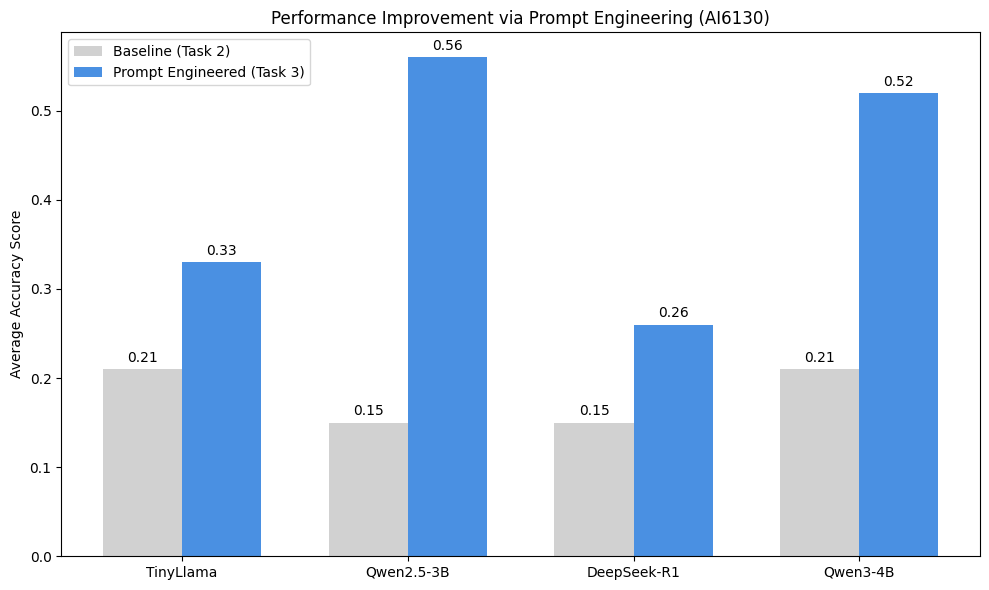

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Pilot results (N = 50)
models = ['TinyLlama', 'Qwen2.5-3B', 'DeepSeek-R1', 'Qwen3-4B']
# We will use the average score across the 3 tasks for each model
baseline_avg = [0.21, 0.15, 0.15, 0.21] # Averages from the baseline table
improved_avg = [0.33, 0.56, 0.26, 0.52] # Averages from the engineered-prompt table

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, baseline_avg, width, label='Baseline (Task 2)', color='#d1d1d1')
rects2 = ax.bar(x + width/2, improved_avg, width, label='Prompt Engineered (Task 3)', color='#4A90E2')

ax.set_ylabel('Average Accuracy Score')
ax.set_title('Pilot run (N=50): baseline vs prompt engineering')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

# Add labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig('pilot_comparison.png', dpi=300)
plt.show()

## 4. Final run (N = 200 per dataset)
Both prompting modes for all 4 models and 3 datasets in one loop. Note the baseline here also shows the answer options. These are the results reported in the README and the report.

--- Loading Datasets (Size: 200) ---

PROCESSING MODEL: TinyLlama/TinyLlama_v1.1



PROCESSING MODEL: Qwen/Qwen2.5-3B-Instruct



PROCESSING MODEL: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B



PROCESSING MODEL: Qwen/Qwen3-4B-Instruct-2507



TABLE 1: BASELINE
                            Model  commonsense_qa  openbookqa   piqa
0                 TinyLlama_v1.1           0.245        0.34  0.420
1            Qwen2.5-3B-Instruct           0.515        0.30  0.515
2  DeepSeek-R1-Distill-Qwen-1.5B           0.275        0.25  0.425
3         Qwen3-4B-Instruct-2507           0.545        0.31  0.475

TABLE 2: IMPROVED
                            Model  commonsense_qa  openbookqa   piqa
0                 TinyLlama_v1.1           0.160       0.265  0.500
1            Qwen2.5-3B-Instruct           0.685       0.325  0.425
2  DeepSeek-R1-Distill-Qwen-1.5B           0.035       0.210  0.435
3         Qwen3-4B-Instruct-2507           0.400       0.310  0.540


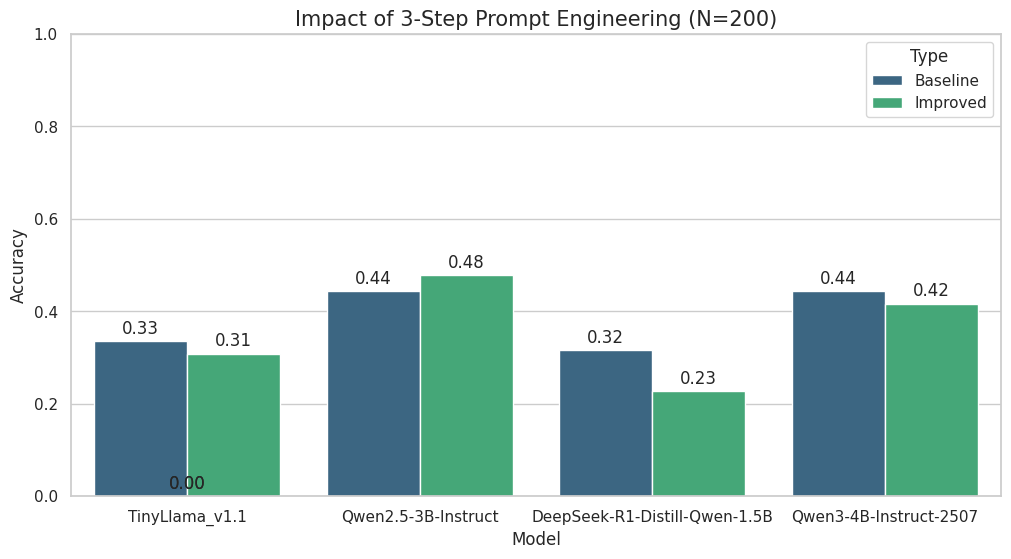

In [ ]:
import torch, gc, re, time, tqdm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

# ==========================================
# 1. CONFIGURATION & DATA PREPARATION
# ==========================================
SAMPLE_SIZE = 200  # larger sample for more stable estimates
model_names = [
    "TinyLlama/TinyLlama_v1.1",
    "Qwen/Qwen2.5-3B-Instruct",
    "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    "Qwen/Qwen3-4B-Instruct-2507"
]

print(f"--- Loading Datasets (Size: {SAMPLE_SIZE}) ---")
eval_datasets = {
    "commonsense_qa": load_dataset("commonsense_qa", split="validation").select(range(SAMPLE_SIZE)),
    "openbookqa": load_dataset("openbookqa", split="validation").select(range(SAMPLE_SIZE)),
    "piqa": grouped_datasets['piqa'][:SAMPLE_SIZE]
}

# ==========================================
# 2. UTILITY FUNCTIONS
# ==========================================
def extract_final_answer(text):
    """Remove <think> blocks (reasoning models) and return the last standalone A-E letter."""
    text = re.sub(r'<think>.*?</think>', '', text, flags=re.DOTALL).strip()
    matches = re.findall(r'\b([A-E])\b', text.upper())
    return matches[-1] if matches else ""

def get_task3_prompt(question, options, task_name):
    """Engineered prompt: role + few-shot examples + output constraint."""
    role = f"You are a specialized expert in {task_name.replace('_', ' ')}."
    examples = (
        "Example 1:\nQuestion: What color is the sky?\nOptions: A: Red, B: Blue, C: Green\nAnswer: B\n\n"
        "Example 2:\nQuestion: Is 2 + 2 equal to 4?\nOptions: A: Yes, B: No\nAnswer: A\n\n"
    )
    instruction = "Solve the question below. Provide ONLY the letter (A, B, C, D, or E) of the correct answer."
    return f"{role}\n\n{examples}{instruction}\n\nQuestion: {question}\nOptions: {options}\nAnswer:"

# ==========================================
# 3. CORE EVALUATION LOOP
# ==========================================
table_1_results = {}
table_2_results = {}

for model_id in model_names:
    print(f"\n{'='*50}\nPROCESSING MODEL: {model_id}\n{'='*50}")

    # Load in float16
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        torch_dtype=torch.float16,
        device_map="auto"
    )

    for task_name, data in eval_datasets.items():
        for mode in ["Baseline", "Improved"]:
            correct = 0
            for item in tqdm.tqdm(data, desc=f"{task_name} ({mode})"):
                # Handle heterogeneous dataset field names
                q = item.get('question', item.get('goal', ""))
                # Handle Option formatting
                if 'choices' in item:
                    opts = item['choices']
                    opts_str = "\n".join([f"{l}: {t}" for l, t in zip(opts['label'], opts['text'])])
                else: # PIQA style
                    opts_str = f"A: {item.get('sol1')}\nB: {item.get('sol2')}"

                # Apply Prompt Logic
                if mode == "Baseline":
                    prompt = f"Question: {q}\nOptions: {opts_str}\nAnswer:"
                else:
                    prompt = get_task3_prompt(q, opts_str, task_name)

                # Inference
                inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
                with torch.no_grad():
                    outputs = model.generate(**inputs, max_new_tokens=15, pad_token_id=tokenizer.eos_token_id)

                response = tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)

                # Evaluation
                pred = extract_final_answer(response)
                gt = str(item.get('answerKey', item.get('label', "")))
                if gt in ["0", "1"]: gt = "A" if gt == "0" else "B" # PIQA Label Fix

                if pred == gt: correct += 1

            # Store Results
            accuracy = correct / SAMPLE_SIZE
            if mode == "Baseline":
                table_1_results[f"{model_id}_{task_name}"] = accuracy
            else:
                table_2_results[f"{model_id}_{task_name}"] = accuracy

    # Free GPU memory before the next model
    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()

# ==========================================
# 4. TABULATION & VISUALIZATION
# ==========================================
# Build DataFrames
df_t1 = pd.DataFrame([{"Model": m.split('/')[-1], **{t: table_1_results[f"{m}_{t}"] for t in eval_datasets}} for m in model_names])
df_t2 = pd.DataFrame([{"Model": m.split('/')[-1], **{t: table_2_results[f"{m}_{t}"] for t in eval_datasets}} for m in model_names])

print("\nTABLE 1: BASELINE\n", df_t1)
print("\nTABLE 2: IMPROVED\n", df_t2)

# Plot average accuracy per model
sns.set_theme(style="whitegrid")
plot_data = []
for m in model_names:
    m_short = m.split('/')[-1]
    b_avg = sum(table_1_results[f"{m}_{t}"] for t in eval_datasets)/3
    i_avg = sum(table_2_results[f"{m}_{t}"] for t in eval_datasets)/3
    plot_data.append([m_short, b_avg, "Baseline"])
    plot_data.append([m_short, i_avg, "Improved"])

plot_df = pd.DataFrame(plot_data, columns=["Model", "Accuracy", "Type"])

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=plot_df, x="Model", y="Accuracy", hue="Type", palette="viridis")
plt.title(f"Impact of 3-Step Prompt Engineering (N={SAMPLE_SIZE})", fontsize=15)
plt.ylim(0, 1.0)

# Add values on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center', xytext = (0, 9), textcoords = 'offset points')

plt.savefig('prompt_engineering_results.png', dpi=300)
plt.show()